# Motor Temperature Prediction
## Person 3 (Baseline & Linear Models) and Person 4 (Model Optimisation & Evaluation)

**Goal:** predict the stator winding temperature of a PMSM motor using only easily measured quantities
(voltages, currents, speed, torque and ambient temperature).

This notebook continues after EDA (Person 1) and preprocessing (Person 2).

### 1. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# in Colab: mount drive and change the path to where measures_v2.csv is
# from google.colab import drive
# drive.mount('/content/drive')
# DATA_PATH = '/content/drive/MyDrive/measures_v2.csv'

DATA_PATH = 'measures_v2.csv'

df = pd.read_csv(DATA_PATH)
print(df.shape)

(1330816, 13)


### 2. Features, target and train/test split

Same choices as the rest of the group:

- **Target:** `stator_winding`
- **Dropped:** `stator_tooth`, `stator_yoke`, `pm` (other temperatures inside the motor, the model would just copy them)
- **Dropped:** `coolant` (it is also a temperature and the problem statement only gives ambient temp, speed, torque, voltage and current)
- `profile_id` is **not** used as an input. We only use it to split the data, so that one whole test run is either fully in train or fully in test.

In [3]:
features = ['u_q', 'u_d', 'i_d', 'i_q', 'motor_speed', 'torque', 'ambient']
target = 'stator_winding'

X = df[features]
y = df[target]
groups = df['profile_id']

# 80/20 split by profile, not by row
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print('train rows:', len(X_train), '| train profiles:', groups_train.nunique())
print('test rows :', len(X_test), '| test profiles :', groups.iloc[test_idx].nunique())
print('common profiles:', len(set(groups_train) & set(groups.iloc[test_idx])))

train rows: 1026423 | train profiles: 55
test rows : 304393 | test profiles : 14


common profiles: 0


In [4]:
# helper to print MAE, RMSE and R2 for a set of predictions
def get_scores(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return round(mae, 3), round(rmse, 3), round(r2, 4)

---
# PERSON 3 — Baseline & Linear Models

We start with the simplest model possible and then make it a bit more complex step by step.

1. **Mean baseline** – always guess the average temperature. Any real model must beat this.
2. **Linear Regression** – temperature = straight-line combination of the inputs.
3. **Polynomial Regression** – also adds squares and products of inputs (e.g. `i_d²`, `i_d × speed`), so it can bend.
4. **Ridge Regression** – linear regression with a penalty that keeps coefficients small.
5. **Lasso Regression** – like Ridge, but can push useless coefficients to exactly zero.

All models are trained on the full training set and tested on the 14 unseen profiles.

In [5]:
# 1. mean baseline
baseline_pred = np.full(len(y_test), y_train.mean())
print('Mean baseline  MAE, RMSE, R2 =', get_scores(y_test, baseline_pred))

Mean baseline  MAE, RMSE, R2 = (25.904, np.float64(30.345), -0.0004)


In [6]:
# 2-5. linear family
# scaling is needed because the inputs are in very different units (rpm vs volts vs amps)
linear_models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Polynomial Regression (deg 2)': make_pipeline(StandardScaler(), PolynomialFeatures(degree=2),
                                                   StandardScaler(), LinearRegression()),
    'Ridge Regression': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso Regression': make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=5000)),
}

p3_results = []
for name, model in linear_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_scores = get_scores(y_train, model.predict(X_train))
    test_scores = get_scores(y_test, model.predict(X_test))
    p3_results.append([name, *test_scores, train_scores[2], round(time.time() - start, 1)])
    print(name, 'done')

p3_table = pd.DataFrame(p3_results, columns=['model', 'test_MAE', 'test_RMSE', 'test_R2', 'train_R2', 'seconds'])
p3_table

Linear Regression done


Polynomial Regression (deg 2) done


Ridge Regression done


Lasso Regression done


,model,test_MAE,test_RMSE,test_R2,train_R2,seconds
0,Linear Regression,16.445,19.934,0.5683,0.4950,0.4
1,Polynomial Regression (deg 2),11.110,14.628,0.7675,0.6936,3.6
2,Ridge Regression,16.445,19.934,0.5683,0.4950,0.3
3,Lasso Regression,16.588,20.009,0.5651,0.4934,0.4


**What the linear coefficients say** (from plain Linear Regression, inputs are scaled so the sizes can be compared):

In [7]:
lin = linear_models['Linear Regression'].named_steps['linearregression']
coef_table = pd.DataFrame({'feature': features, 'coefficient': lin.coef_}).sort_values('coefficient', key=abs, ascending=False)
coef_table

,feature,coefficient
5,torque,18.080882
3,i_q,-17.505801
2,i_d,-17.129373
6,ambient,9.986007
0,u_q,-1.478087
4,motor_speed,-0.371672
1,u_d,0.102544


In [8]:
lasso = linear_models['Lasso Regression'].named_steps['lasso']
print('Lasso coefficients:')
print(pd.Series(lasso.coef_, index=features).round(3))

Lasso coefficients:
u_q            -1.900
u_d            -0.516
i_d           -17.425
i_q            -0.000
motor_speed    -0.000
torque          0.000
ambient         9.836
dtype: float64


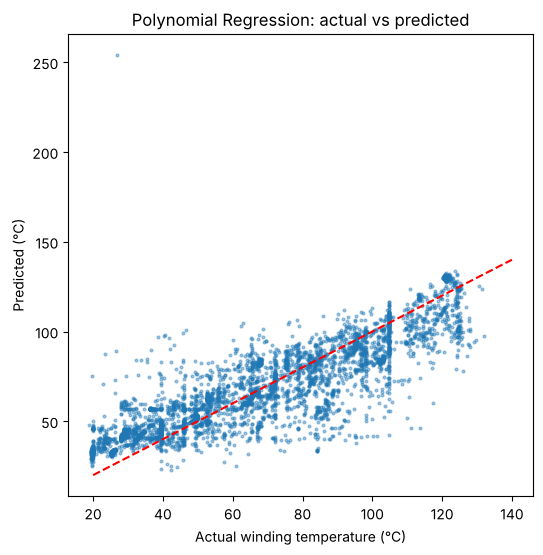

In [9]:
# actual vs predicted for the best linear-family model (on a sample so the plot is readable)
best_linear = linear_models['Polynomial Regression (deg 2)']
sample = np.random.RandomState(0).choice(len(X_test), 5000, replace=False)
pred = best_linear.predict(X_test.iloc[sample])

plt.figure(figsize=(6, 6))
plt.scatter(y_test.iloc[sample], pred, s=4, alpha=0.4)
plt.plot([20, 140], [20, 140], 'r--')
plt.xlabel('Actual winding temperature (°C)')
plt.ylabel('Predicted (°C)')
plt.title('Polynomial Regression: actual vs predicted')
plt.show()

### Person 3 — summary

| Model | Test MAE (°C) | Test RMSE (°C) | Test R² |
|---|---|---|---|
| Mean baseline (always guess average) | 25.90 | 30.35 | 0.00 |
| Linear Regression | 16.45 | 19.93 | 0.568 |
| Ridge Regression | 16.45 | 19.93 | 0.568 |
| Lasso Regression | 16.59 | 20.01 | 0.565 |
| **Polynomial Regression (degree 2)** | **11.11** | **14.63** | **0.768** |

- Every model beats the mean baseline, so the inputs really do carry information about the winding temperature.
- Linear, Ridge and Lasso are almost identical. With 1 million training rows the penalty in Ridge/Lasso barely changes anything.
- Lasso set the coefficients of `i_q`, `motor_speed` and `torque` to zero. These columns carry almost the same information as each other (torque comes mostly from `i_q`), so Lasso keeps only what it needs.
- Polynomial Regression is the clear winner of this group (R² 0.57 → 0.77). Heat in a wire grows with current², and squared terms like `i_d²` are exactly what polynomial features add.
- Train R² is not higher than test R² for any of these models, so there is no overfitting. The straight-line models are simply too simple (underfitting).
- Extra test (below): adding the engineered feature `i_squared = i_d² + i_q²` lifts Linear/Ridge/Lasso from R² 0.568 to 0.584, but does not help the polynomial models.

---
### Extra test: engineered feature `i_squared = i_d² + i_q²` (suggested by Mananjit)

Heat in the winding comes from current squared (copper loss, I²R). So we tried giving the models the
total current squared directly as one extra column and checked if the linear-family models improve.
Same split, same settings as above, only one extra input.

In [6]:
df['i_squared'] = df['i_d']**2 + df['i_q']**2
print('correlation of i_squared with winding temp:', round(df['i_squared'].corr(df[target]), 4))

features_new = features + ['i_squared']
X_train_new = df[features_new].iloc[train_idx]
X_test_new = df[features_new].iloc[test_idx]

compare_models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge Regression': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso Regression': make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=5000)),
    'Polynomial Regression (deg 2)': make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), LinearRegression()),
    'Polynomial (deg 3) + Ridge': make_pipeline(StandardScaler(), PolynomialFeatures(3), StandardScaler(), Ridge(alpha=1)),
}

rows = []
for name, model in compare_models.items():
    for label, Xtr, Xte in [('7 features', X_train, X_test), ('7 + i_squared', X_train_new, X_test_new)]:
        m = clone(model)
        m.fit(Xtr, y_train)
        rows.append([name, label, *get_scores(y_test, m.predict(Xte)), get_scores(y_train, m.predict(Xtr))[2]])
        if name == 'Lasso Regression' and label == '7 + i_squared':
            lasso_new = m.named_steps['lasso']

feature_test = pd.DataFrame(rows, columns=['model', 'inputs', 'test_MAE', 'test_RMSE', 'test_R2', 'train_R2'])
feature_test.to_csv('engineered_feature_test.csv', index=False)
feature_test

correlation of i_squared with winding temp: 0.5329


,model,inputs,test_MAE,test_RMSE,test_R2,train_R2
0,Linear Regression,7 features,16.445,19.934,0.5683,0.4950
1,Linear Regression,7 + i_squared,16.051,19.579,0.5835,0.5159
2,Ridge Regression,7 features,16.445,19.934,0.5683,0.4950
3,Ridge Regression,7 + i_squared,16.051,19.579,0.5835,0.5159
4,Lasso Regression,7 features,16.588,20.009,0.5651,0.4934
5,Lasso Regression,7 + i_squared,16.204,19.592,0.5830,0.5130
6,Polynomial Regression (deg 2),7 features,11.110,14.628,0.7675,0.6936
7,Polynomial Regression (deg 2),7 + i_squared,11.258,14.906,0.7586,0.7097
8,Polynomial (deg 3) + Ridge,7 features,9.801,14.818,0.7615,0.7690
9,Polynomial (deg 3) + Ridge,7 + i_squared,9.647,14.902,0.7588,0.7787


In [7]:
print('Lasso coefficients with i_squared:')
print(pd.Series(lasso_new.coef_, index=features_new).round(3))

Lasso coefficients with i_squared:
u_q            -6.612
u_d            -1.133
i_d            -0.000
i_q            -0.437
motor_speed    12.902
torque         -0.000
ambient         9.894
i_squared      11.217
dtype: float64


**Result of the extra test**

- **Linear, Ridge, Lasso improve a little:** R² 0.568 → 0.584, MAE 16.45 → 16.05 °C. A straight line cannot make squares by itself, so giving it current² directly helps.
- **Lasso now picks `i_squared` as one of its most important inputs** and drops `i_d` and `torque` to zero. It prefers total current² over the separate currents, which matches the physics.
- **Polynomial models do not improve** (deg 2: 0.768 → 0.759, deg 3 + Ridge: 0.762 → 0.759). Polynomial features already contain i_d² and i_q², so the new column adds nothing new. It only adds even higher powers (like i_d⁴), which make the model fit training data a bit more and test data a bit less.
- **The best model does not change:** the tuned MLP (R² 0.811) is still the best. We keep the original 7 features for the final models and mention i_squared as a useful feature for the simple linear models.

---
# PERSON 4 — Model Optimisation & Evaluation

Three jobs here:

1. **Cross-validation** – instead of trusting one split, train/test 5 times on different groups of profiles and average.
2. **Hyperparameter tuning (GridSearchCV)** – try many settings for each model and keep the best.
3. **Overfitting check** – compare training score vs test score.

Cross-validation always uses **GroupKFold**: a profile is never in the training part and the validation part at the same time.

To keep the run time reasonable, tuning is done on a sample of **1000 rows from each training profile** (≈55,000 rows).
The final chosen models are then retrained on the full training set.

In [10]:
# sample up to 1000 rows from each training profile
train_df = X_train.copy()
train_df[target] = y_train
train_df['profile_id'] = groups_train

small = train_df.groupby('profile_id').sample(n=1000, replace=True, random_state=42).drop_duplicates()
X_small = small[features]
y_small = small[target]
groups_small = small['profile_id']

print('tuning sample rows:', len(small), '| profiles:', groups_small.nunique())

cv = GroupKFold(n_splits=5)
scoring = {'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}

tuning sample rows: 52868 | profiles: 55


### 4.1 Cross-validation with default settings (before tuning)

In [11]:
cv_models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Polynomial (deg 2)': make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), Ridge()),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=5000)),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'MLP Neural Network': make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200,
                                                                       early_stopping=True, random_state=42)),
}

cv_rows = []
for name, model in cv_models.items():
    s = cross_validate(model, X_small, y_small, groups=groups_small, cv=cv, scoring=scoring,
                       return_train_score=True, n_jobs=-1)
    cv_rows.append([name,
                    round(-s['test_mae'].mean(), 3),
                    round(-s['test_rmse'].mean(), 3),
                    round(s['test_r2'].mean(), 4),
                    round(s['test_r2'].std(), 4),
                    round(s['train_r2'].mean(), 4)])
    print(name, 'done')

cv_table = pd.DataFrame(cv_rows, columns=['model', 'cv_MAE', 'cv_RMSE', 'cv_R2', 'cv_R2_std', 'train_R2'])
cv_table.sort_values('cv_R2', ascending=False)

Linear Regression done


Polynomial (deg 2) done
Ridge done


Lasso done


HistGradientBoosting done


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network done


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,cv_MAE,cv_RMSE,cv_R2,cv_R2_std,train_R2
5,MLP Neural Network,14.463,19.055,0.5064,0.0426,0.7778
4,HistGradientBoosting,15.237,19.303,0.4902,0.0878,0.7951
1,Polynomial (deg 2),13.182,19.893,0.4129,0.3636,0.6734
0,Linear Regression,17.360,21.404,0.3717,0.1156,0.4503
2,Ridge,17.361,21.404,0.3717,0.1156,0.4503
3,Lasso,17.446,21.420,0.3706,0.1155,0.4484


`cv_R2_std` shows how much the score changes from fold to fold. A big value means the model works well on some profiles and badly on others.

### 4.2 Hyperparameter tuning with GridSearchCV
We tune the three most promising models. GridSearchCV tries every combination in the grid with 5-fold GroupKFold and keeps the one with the lowest RMSE.

In [12]:
grids = {
    'Ridge': (
        make_pipeline(StandardScaler(), PolynomialFeatures(), StandardScaler(), Ridge()),
        {'polynomialfeatures__degree': [1, 2, 3],
         'ridge__alpha': [0.1, 1, 10, 100]}
    ),
    'HistGradientBoosting': (
        HistGradientBoostingRegressor(random_state=42),
        {'learning_rate': [0.05, 0.1],
         'max_leaf_nodes': [15, 31],
         'l2_regularization': [0, 1.0]}
    ),
    'MLP Neural Network': (
        make_pipeline(StandardScaler(), MLPRegressor(max_iter=200, early_stopping=True, random_state=42)),
        {'mlpregressor__hidden_layer_sizes': [(32,), (64, 32), (128, 64)],
         'mlpregressor__alpha': [0.0001, 0.01]}
    ),
}

best_models = {}
tuning_rows = []
for name, (model, grid) in grids.items():
    start = time.time()
    search = GridSearchCV(model, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X_small, y_small, groups=groups_small)
    best_models[name] = search.best_estimator_
    tuning_rows.append([name, search.best_params_, round(-search.best_score_, 3), round(time.time() - start)])
    print(name, '->', search.best_params_)

tuning_table = pd.DataFrame(tuning_rows, columns=['model', 'best_params', 'cv_RMSE', 'seconds'])
tuning_table

Ridge -> {'polynomialfeatures__degree': 3, 'ridge__alpha': 1}


HistGradientBoosting -> {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_leaf_nodes': 15}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Neural Network -> {'mlpregressor__alpha': 0.01, 'mlpregressor__hidden_layer_sizes': (128, 64)}


,model,best_params,cv_RMSE,seconds
0,Ridge,"{'polynomialfeatures__degree': 3, 'ridge__alph...",15.878,3
1,HistGradientBoosting,"{'l2_regularization': 1.0, 'learning_rate': 0....",19.186,8
2,MLP Neural Network,"{'mlpregressor__alpha': 0.01, 'mlpregressor__h...",17.648,732


For Ridge we also tuned the polynomial degree, so this one search covers Linear (degree 1), Polynomial (degree 2/3) and Ridge together.

### 4.3 Final test on unseen profiles + overfitting check
Each tuned model is retrained on the **full training set** (≈1 million rows) and tested **once** on the 14 test profiles.

In [13]:
final_rows = []
for name, model in best_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_mae, train_rmse, train_r2 = get_scores(y_train, model.predict(X_train))
    test_mae, test_rmse, test_r2 = get_scores(y_test, model.predict(X_test))
    final_rows.append([name, train_r2, test_r2, round(train_r2 - test_r2, 4), test_mae, test_rmse, round(time.time() - start)])
    print(name, 'done')

final_table = pd.DataFrame(final_rows, columns=['model', 'train_R2', 'test_R2', 'gap', 'test_MAE', 'test_RMSE', 'seconds'])
final_table.sort_values('test_R2', ascending=False)

Ridge done


HistGradientBoosting done


MLP Neural Network done


,model,train_R2,test_R2,gap,test_MAE,test_RMSE,seconds
2,MLP Neural Network,0.8688,0.8110,0.0578,9.069,13.191,4049
0,Ridge,0.7690,0.7615,0.0075,9.801,14.818,8
1,HistGradientBoosting,0.7280,0.6374,0.0906,14.204,18.270,5


**How to read the gap (train R² − test R²):**
- small gap and both low → underfitting (model too simple)
- big gap → overfitting (model memorised the training profiles)
- small gap and both high → good fit

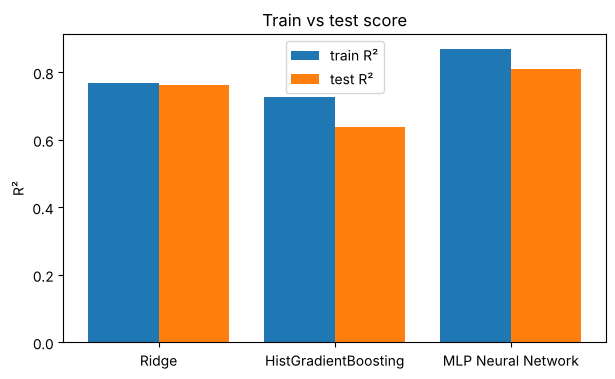

In [14]:
plt.figure(figsize=(7, 4))
x = np.arange(len(final_table))
plt.bar(x - 0.2, final_table['train_R2'], 0.4, label='train R²')
plt.bar(x + 0.2, final_table['test_R2'], 0.4, label='test R²')
plt.xticks(x, final_table['model'])
plt.ylabel('R²')
plt.title('Train vs test score')
plt.legend()
plt.show()

In [15]:
# error for each test profile with the best model
best_name = final_table.sort_values('test_R2', ascending=False).iloc[0]['model']
best = best_models[best_name]

test_df = X_test.copy()
test_df['actual'] = y_test
test_df['predicted'] = best.predict(X_test)
test_df['abs_error'] = (test_df['actual'] - test_df['predicted']).abs()
test_df['profile_id'] = groups.iloc[test_idx]

per_profile = test_df.groupby('profile_id')['abs_error'].mean().round(2).sort_values(ascending=False)
print('Best model:', best_name)
print('Mean absolute error for each test profile (°C):')
per_profile

Best model: MLP Neural Network
Mean absolute error for each test profile (°C):


profile_id
43    16.95
71    13.24
11    13.05
14    11.48
20    11.16
45    10.72
59    10.63
56    10.22
7      9.32
6      8.70
65     8.22
2      5.13
26     3.20
12     2.02
Name: abs_error, dtype: float64

In [16]:
# save results for Person 5
p3_table.to_csv('person3_linear_results.csv', index=False)
cv_table.to_csv('person4_cv_results.csv', index=False)
tuning_table.to_csv('person4_tuning_results.csv', index=False)
final_table.to_csv('person4_final_test_results.csv', index=False)
print('saved')

saved


### Person 4 — summary

**Cross-validation (5-fold GroupKFold, default settings)**
- MLP had the best CV R² (0.506) and also the most stable one (std 0.043).
- Polynomial (deg 2) looked good on average but its R² jumped a lot between folds (std 0.36), so it works very well on some profiles and badly on others.
- CV scores are lower than the final test scores because the CV uses a smaller sample and some training profiles are much harder to predict than the test profiles.

**Tuning (GridSearchCV)**

| Model | Best settings |
|---|---|
| Polynomial + Ridge | degree = 3, alpha = 1 |
| HistGradientBoosting | learning_rate = 0.05, max_leaf_nodes = 15, l2_regularization = 1.0 |
| MLP Neural Network | hidden layers = (128, 64), alpha = 0.01 |

**Final test on the 14 unseen profiles (models retrained on all 1,026,423 training rows)**

| Model | Train R² | Test R² | Gap | Test MAE (°C) | Test RMSE (°C) |
|---|---|---|---|---|---|
| **MLP Neural Network (tuned)** | 0.869 | **0.811** | 0.058 | **9.07** | **13.19** |
| Polynomial (deg 3) + Ridge (tuned) | 0.769 | 0.762 | 0.008 | 9.80 | 14.82 |
| HistGradientBoosting (tuned) | 0.728 | 0.637 | 0.091 | 14.20 | 18.27 |

- **Best model: tuned MLP Neural Network.** It explains about 81% of the temperature variation, with an average error of about 9 °C.
- Tuning helped. The untuned MLP earlier in the project gave R² 0.74; the tuned one gives 0.81.
- Polynomial + Ridge comes very close (0.76), trains in seconds instead of an hour, and has almost no gap. It is a good simple alternative.
- HistGradientBoosting has the biggest gap (0.09), so it overfits the training profiles the most.
- Error depends a lot on the profile: profile 12 is predicted within about 2 °C, profile 43 is off by about 17 °C on average.

Note: training the final MLP on all rows is slow (about 1 hour on a 2-core machine, roughly 15–20 minutes on Colab).